# SmartFactory AI - Etape 1 : Prétraitement + Analyse exploratoire
Dataset : AI4I 2020 Predictive Maintenance (10 000 lignes).
Place le fichier `ai4i2020.csv` dans le dossier `data/`.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
Path("models").mkdir(exist_ok=True)
Path("data").mkdir(exist_ok=True)  

## 2. Chargement et nettoyage des noms de colonnes

In [2]:
csv_path = Path("data/ai4i2020.csv")

if not csv_path.exists():
    csv_path = Path("data/ai4i2020.csv")

if not csv_path.exists():
    raise FileNotFoundError(
        f"Fichier ai4i2020.csv introuvable depuis {Path.cwd()}."
    )

df = pd.read_csv(csv_path)

# Air temperature [K] -> Air_temperature
df.columns = (df.columns
              .str.replace(r"\[.*?\]", "", regex=True)
              .str.strip()
              .str.replace(" ", "_"))
print(df.columns.tolist())
df.head()

['UDI', 'Product_ID', 'Type', 'Air_temperature', 'Process_temperature', 'Rotational_speed', 'Torque', 'Tool_wear', 'Machine_failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product_ID,Type,Air_temperature,Process_temperature,Rotational_speed,Torque,Tool_wear,Machine_failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Aperçu général

In [3]:
print("Dimensions :", df.shape)
df.info()

Dimensions : (10000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   UDI                  10000 non-null  int64  
 1   Product_ID           10000 non-null  object 
 2   Type                 10000 non-null  object 
 3   Air_temperature      10000 non-null  float64
 4   Process_temperature  10000 non-null  float64
 5   Rotational_speed     10000 non-null  int64  
 6   Torque               10000 non-null  float64
 7   Tool_wear            10000 non-null  int64  
 8   Machine_failure      10000 non-null  int64  
 9   TWF                  10000 non-null  int64  
 10  HDF                  10000 non-null  int64  
 11  PWF                  10000 non-null  int64  
 12  OSF                  10000 non-null  int64  
 13  RNF                  10000 non-null  int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 1.1+ MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air_temperature,10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process_temperature,10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational_speed,10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque,10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool_wear,10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine_failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


## 4. Qualité des données : valeurs manquantes et doublons

In [5]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum())
print("\nDoublons (lignes entières) :", df.duplicated().sum())
print("Doublons Product_ID :", df["Product_ID"].duplicated().sum())

Valeurs manquantes par colonne :
UDI                    0
Product_ID             0
Type                   0
Air_temperature        0
Process_temperature    0
Rotational_speed       0
Torque                 0
Tool_wear              0
Machine_failure        0
TWF                    0
HDF                    0
PWF                    0
OSF                    0
RNF                    0
dtype: int64

Doublons (lignes entières) : 0
Doublons Product_ID : 0


## 5. Variable cible : déséquilibre des classes

Machine_failure
0    9661
1     339
Name: count, dtype: int64
Machine_failure
0    96.61
1     3.39
Name: proportion, dtype: float64


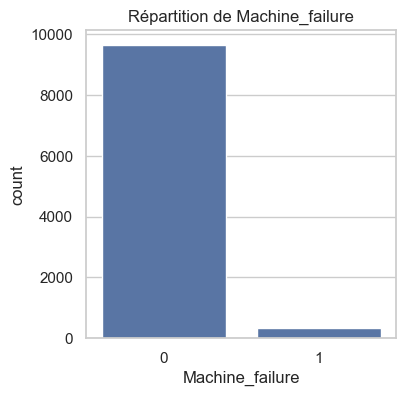

In [6]:
counts = df["Machine_failure"].value_counts()
print(counts)
print((df["Machine_failure"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(4, 4))
sns.countplot(data=df, x="Machine_failure")
plt.title("Répartition de Machine_failure")
plt.show()

## 6. Types de pannes et risque de fuite de données
`TWF, HDF, PWF, OSF, RNF` sont les **causes** de la panne : on ne doit pas les utiliser comme features.

In [7]:
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print("Nombre de pannes par type :")
print(df[modes].sum())

# Verification de la fuite : panne = au moins un mode de panne ?
any_mode = (df[modes].sum(axis=1) > 0).astype(int)
print("\nCohérence Machine_failure vs modes :")
print(pd.crosstab(df["Machine_failure"], any_mode, rownames=["Machine_failure"], colnames=["Au moins un mode"]))

Nombre de pannes par type :
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

Cohérence Machine_failure vs modes :
Au moins un mode     0    1
Machine_failure            
0                 9643   18
1                    9  330


In [8]:
import sys, sklearn
print(sys.executable, sklearn.__version__)

c:\Users\ghait\AppData\Local\Programs\Python\Python313\python.exe 1.8.0


## 7. Valeurs aberrantes (règle de l'IQR)

Nombre d'outliers par variable :
Air_temperature          0
Process_temperature      0
Rotational_speed       418
Torque                  69
Tool_wear                0
dtype: int64

Taux de pannes - lignes avec outlier : 15.69 %
Taux de pannes - autres lignes       : 2.8 %


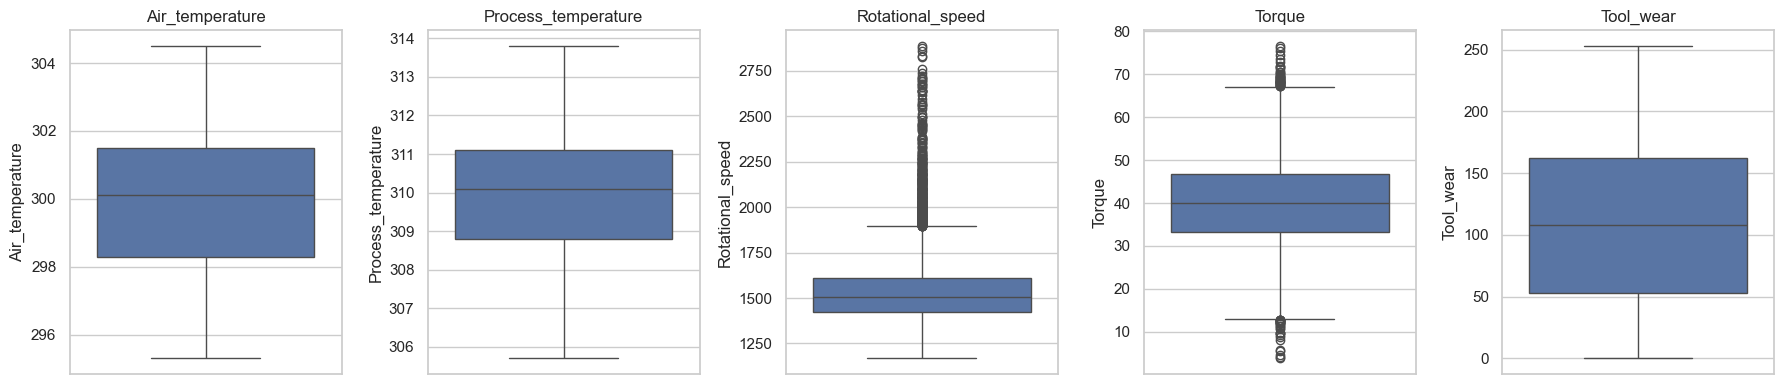

In [9]:
num_cols = ["Air_temperature", "Process_temperature", "Rotational_speed", "Torque", "Tool_wear"]

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr))

out = pd.DataFrame({c: iqr_outliers(df[c]) for c in num_cols})
print("Nombre d'outliers par variable :")
print(out.sum())

# Taux de pannes parmi les outliers vs reste
any_out = out.any(axis=1)
print("\nTaux de pannes - lignes avec outlier :", round(df.loc[any_out, "Machine_failure"].mean() * 100, 2), "%")
print("Taux de pannes - autres lignes       :", round(df.loc[~any_out, "Machine_failure"].mean() * 100, 2), "%")

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

> **Décision :** on **conserve** les outliers. Dans la maintenance prédictive, les valeurs extrêmes sont souvent précisément les situations qui précèdent une panne. Les supprimer ferait perdre de l'information. Justifie ce choix dans ton rapport.

## 8. Feature engineering
Variables construites à partir de la physique du système :
- `Temp_diff` : écart process - air (dissipation thermique)
- `Power` : puissance mécanique en watts = couple x vitesse angulaire
- `Torque_x_Wear` : surcharge liée à l'usure

In [10]:
df["Temp_diff"] = df["Process_temperature"] - df["Air_temperature"]
df["Power"] = df["Torque"] * df["Rotational_speed"] * 2 * np.pi / 60
df["Torque_x_Wear"] = df["Torque"] * df["Tool_wear"]

df[["Temp_diff", "Power", "Torque_x_Wear"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Temp_diff,10000.0,10.000630,1.001094,7.60000,9.300000,9.800000,11.000000,12.100000
Power,10000.0,6279.744953,1067.418295,1148.44061,5561.184484,6271.027344,7003.002724,10469.923005
Torque_x_Wear,10000.0,4314.664550,2826.567692,0.00000,1963.650000,4012.950000,6279.000000,16497.000000


## 9. Analyse exploratoire

### 9.1 Distribution des variables selon l'état de la machine

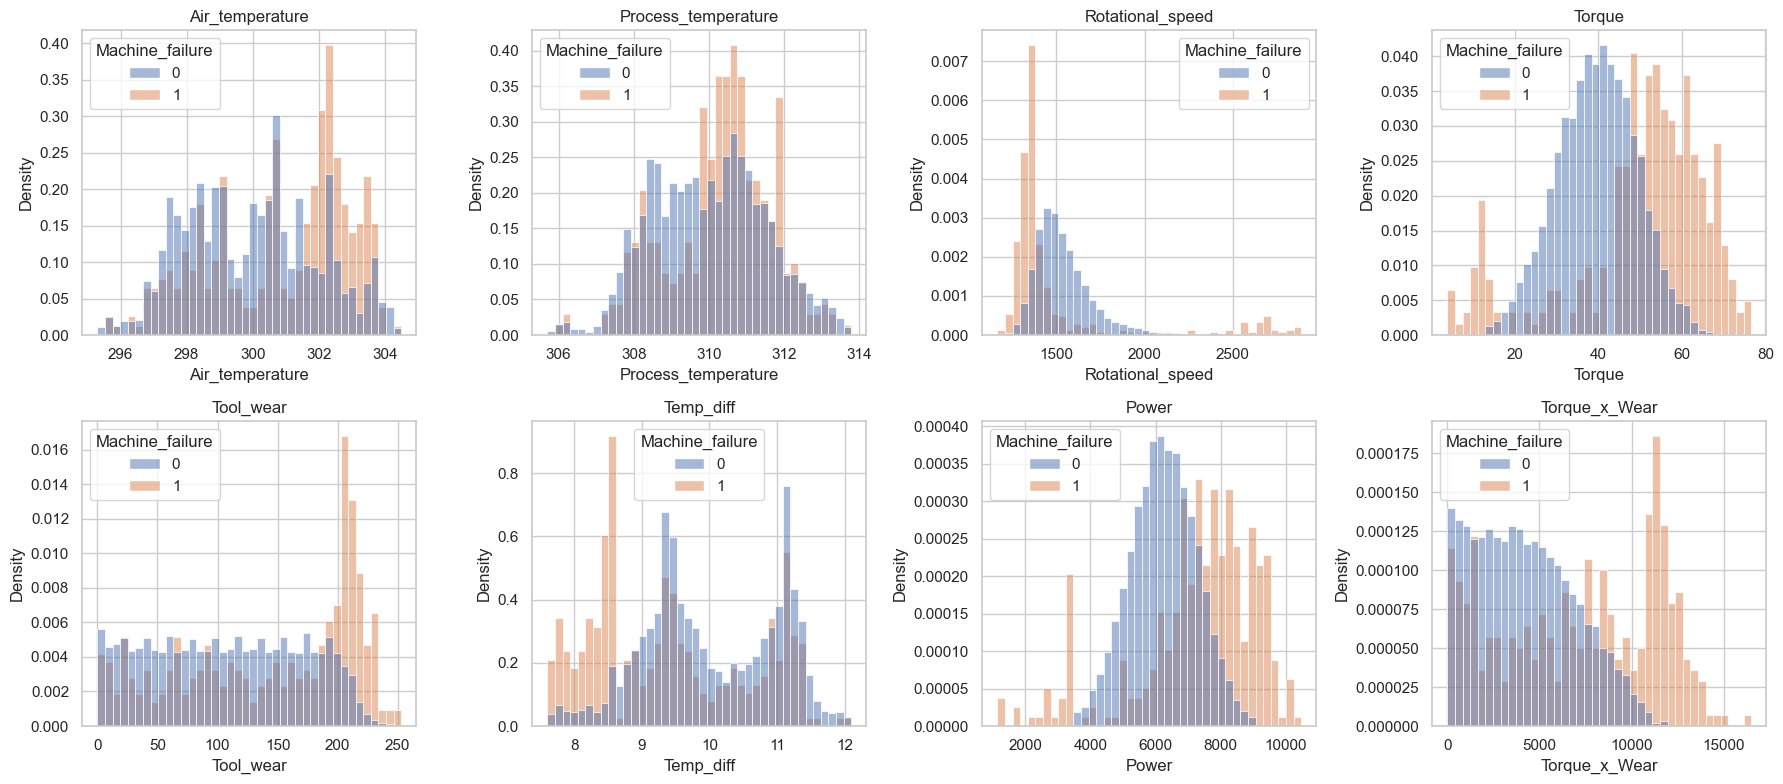

In [11]:
features_eda = num_cols + ["Temp_diff", "Power", "Torque_x_Wear"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), features_eda):
    sns.histplot(data=df, x=c, hue="Machine_failure", stat="density",
                 common_norm=False, bins=40, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

### 9.2 Boxplots par état de la machine

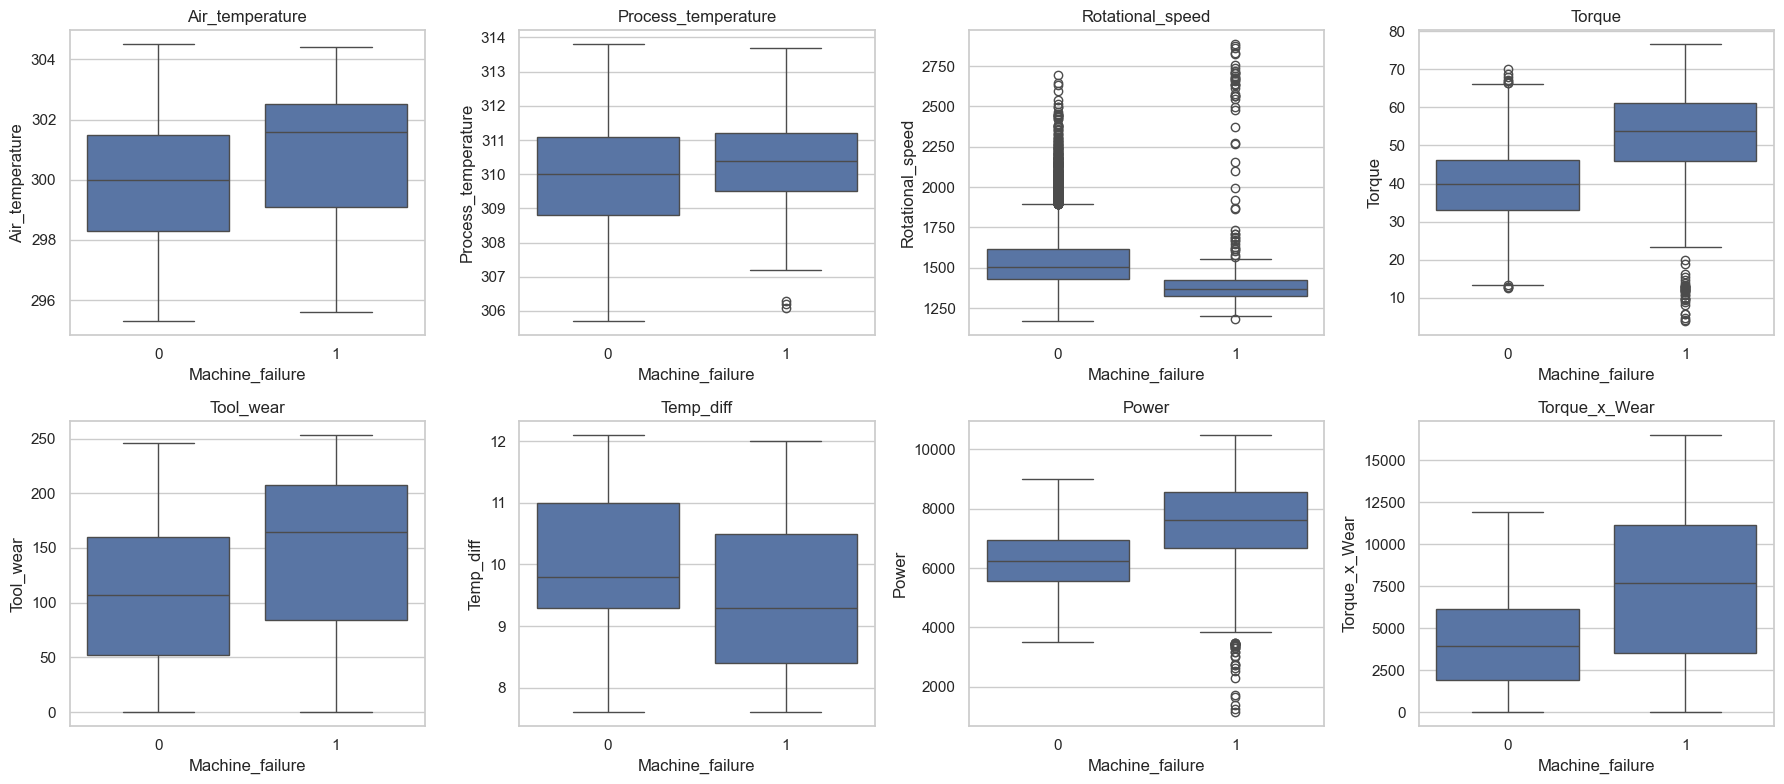

Machine_failure,0,1
Air_temperature,299.97,300.89
Process_temperature,310.00,310.29
Rotational_speed,1540.26,1496.49
Torque,39.63,50.17
Tool_wear,106.69,143.78
Temp_diff,10.02,9.40
Power,6244.55,7282.82
Torque_x_Wear,4213.84,7187.94


In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), features_eda):
    sns.boxplot(data=df, x="Machine_failure", y=c, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

# Moyennes par classe
df.groupby("Machine_failure")[features_eda].mean().T.round(2)

### 9.3 Effet du type de produit (L / M / H)

,Nb machines,Nb pannes,Taux de pannes (%)
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77


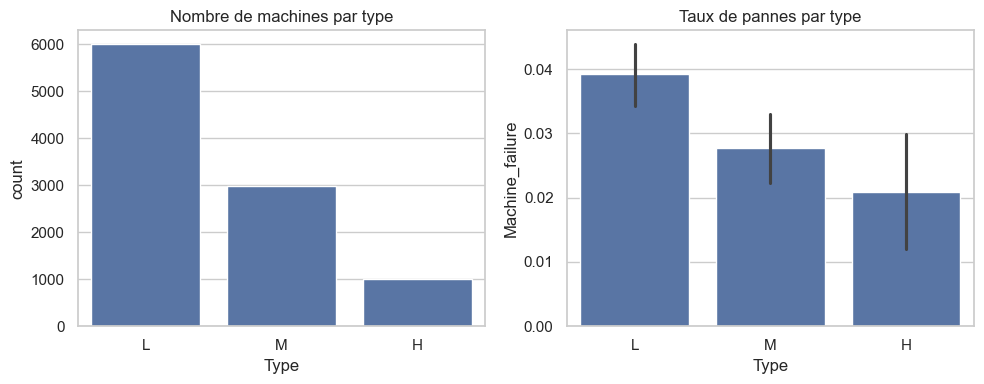

In [13]:
rate = df.groupby("Type")["Machine_failure"].agg(["count", "sum", "mean"])
rate["mean"] = (rate["mean"] * 100).round(2)
rate.columns = ["Nb machines", "Nb pannes", "Taux de pannes (%)"]
display(rate)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x="Type", order=["L", "M", "H"], ax=axes[0])
axes[0].set_title("Nombre de machines par type")
sns.barplot(data=df, x="Type", y="Machine_failure", order=["L", "M", "H"], ax=axes[1])
axes[1].set_title("Taux de pannes par type")
plt.tight_layout()
plt.show()

### 9.4 Corrélations

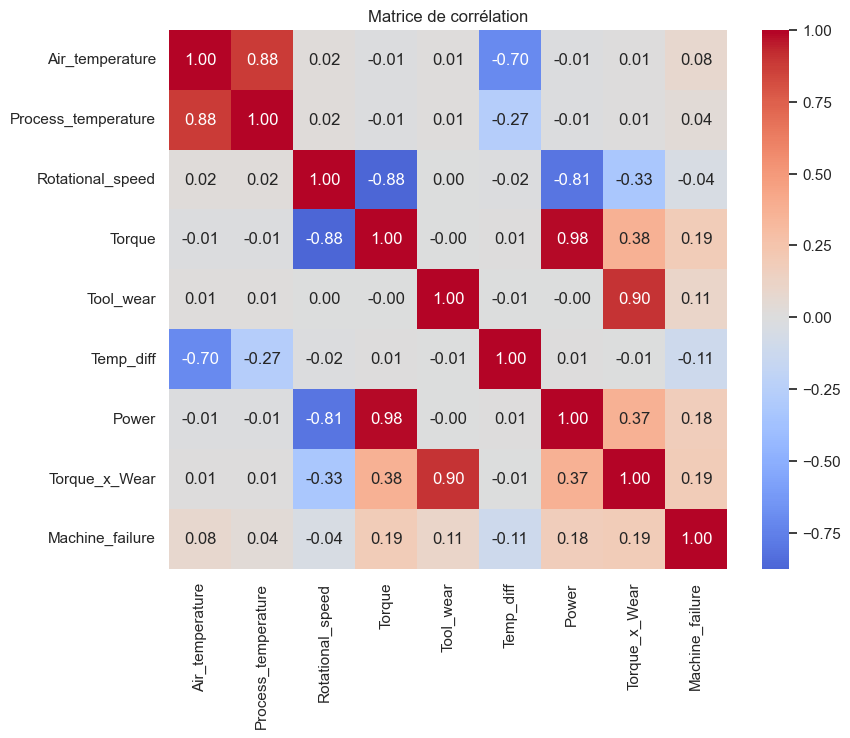

Corrélation avec Machine_failure :
Torque                 0.191
Torque_x_Wear          0.190
Power                  0.176
Temp_diff             -0.112
Tool_wear              0.105
Air_temperature        0.083
Rotational_speed      -0.044
Process_temperature    0.036
Name: Machine_failure, dtype: float64


In [14]:
corr_cols = features_eda + ["Machine_failure"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

print("Corrélation avec Machine_failure :")
print(df[corr_cols].corr()["Machine_failure"].drop("Machine_failure").sort_values(key=abs, ascending=False).round(3))

> **A observer :** `Air_temperature` et `Process_temperature` sont fortement corrélées entre elles, et `Power` est liée à `Torque`. Cela est utile à discuter pour la PCA (redondance entre variables).

### 9.5 Pannes par type de défaillance

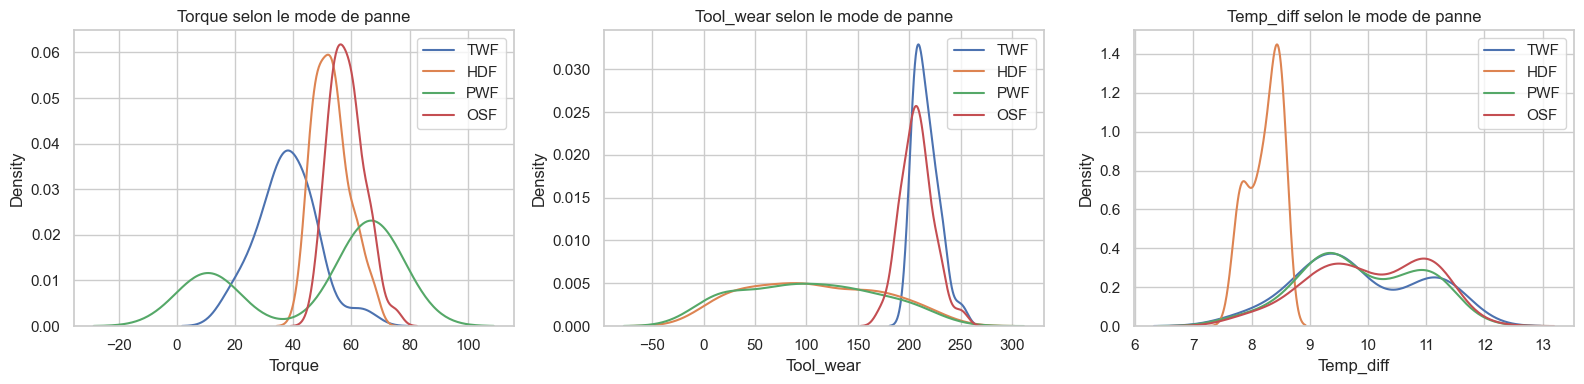

In [15]:
fail = df[df["Machine_failure"] == 1]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["Torque", "Tool_wear", "Temp_diff"]):
    for m in ["TWF", "HDF", "PWF", "OSF"]:
        sns.kdeplot(df.loc[df[m] == 1, c], label=m, ax=ax, warn_singular=False)
    ax.set_title(c + " selon le mode de panne")
    ax.legend()
plt.tight_layout()
plt.show()

## 10. Préparation pour la modélisation
- Retrait des identifiants et des colonnes de fuite
- Encodage de `Type` (ordinal : L < M < H)
- Split **stratifié** 80/20
- Normalisation : scaler ajusté **uniquement sur le train**

In [16]:
# Encodage ordinal de Type
df["Type_enc"] = df["Type"].map({"L": 0, "M": 1, "H": 2})

feature_cols = num_cols + ["Temp_diff", "Power", "Torque_x_Wear", "Type_enc"]
X = df[feature_cols]
y = df["Machine_failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train :", X_train.shape, "- taux de pannes :", round(y_train.mean() * 100, 2), "%")
print("Test  :", X_test.shape, "- taux de pannes :", round(y_test.mean() * 100, 2), "%")

Train : (8000, 9) - taux de pannes : 3.39 %
Test  : (2000, 9) - taux de pannes : 3.4 %


In [17]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)

X_train_s.describe().T[["mean", "std"]].round(3)

,mean,std
Air_temperature,0.0,1.0
Process_temperature,0.0,1.0
Rotational_speed,0.0,1.0
Torque,-0.0,1.0
Tool_wear,-0.0,1.0
Temp_diff,-0.0,1.0
Power,0.0,1.0
Torque_x_Wear,-0.0,1.0
Type_enc,0.0,1.0


## 11. Sauvegarde

In [18]:
df.to_csv("data/ai4i_clean.csv", index=False)
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(feature_cols, "models/feature_cols.pkl")
X_train_s.assign(target=y_train).to_csv("data/train.csv", index=False)
X_test_s.assign(target=y_test).to_csv("data/test.csv", index=False)
print("Fichiers sauvegardés.")

Fichiers sauvegardés.


## Résumé à retenir pour le rapport
1. Aucune valeur manquante, aucun doublon.
2. Classe « panne » minoritaire (~3,4 %) : déséquilibre à traiter.
3. TWF/HDF/PWF/OSF/RNF exclues des features (fuite de données).
4. Outliers conservés (information utile pour la détection de pannes).
5. 3 variables construites : `Temp_diff`, `Power`, `Torque_x_Wear`.
6. Split stratifié, scaler ajusté sur le train uniquement.